In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Detect project root.
# This works both if the notebook is opened from the repo root
# and if it is opened from the notebooks/ folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())
print("configs/req1.yaml exists:", (PROJECT_ROOT / "configs" / "req1.yaml").exists())
print("experiments/run_req1.py exists:", (PROJECT_ROOT / "experiments" / "run_req1.py").exists())
print("ola package exists:", (PROJECT_ROOT / "ola").exists())

PROJECT_ROOT: /Users/foadzahedilabaf/Projects/ola-project
PROJECT_ROOT exists: True
configs/req1.yaml exists: True
experiments/run_req1.py exists: True
ola package exists: True


In [3]:
from ola.environments.single_campaign import SingleCampaignEnvironment
from ola.algorithms.ucb1 import UCB1
from ola.algorithms.budgeted_ucb import BudgetedUCB

from experiments.run_req1 import (
    load_req1_config,
    compute_req1_benchmarks,
    run_algorithm,
    save_algorithm_results,
)

print("All Req 1 project imports worked correctly.")

All Req 1 project imports worked correctly.


In [4]:
config_path = PROJECT_ROOT / "configs" / "req1.yaml"

config = load_req1_config(config_path)

print("Loaded config from:", config_path)
print("Top-level config keys:")
for key in config.keys():
    print("-", key)

print("\nFull config:")
config

Loaded config from: /Users/foadzahedilabaf/Projects/ola-project/configs/req1.yaml
Top-level config keys:
- experiment
- campaign
- bids
- environment
- outputs

Full config:


{'experiment': {'name': 'req1_single_campaign',
  'random_seed': 42,
  'horizon': 1000},
 'campaign': {'value': 1.0, 'initial_budget': 300.0},
 'bids': {'values': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},
 'environment': {'competing_bid_distribution': 'uniform',
  'min_competing_bid': 0.0,
  'max_competing_bid': 1.0},
 'outputs': {'results_dir': 'results/raw',
  'ucb1_results_file': 'results/raw/req1_ucb1.csv',
  'budgeted_ucb_results_file': 'results/raw/req1_budgeted_ucb.csv'}}

In [5]:
experiment_config = config["experiment"]
campaign_config = config["campaign"]
bids_config = config["bids"]
environment_config = config["environment"]
outputs_config = config["outputs"]

experiment_name = experiment_config["name"]
random_seed = int(experiment_config["random_seed"])
horizon = int(experiment_config["horizon"])

value = float(campaign_config["value"])
initial_budget = float(campaign_config["initial_budget"])
rho = initial_budget / horizon

bids = np.array(bids_config["values"], dtype=float)

competing_bid_distribution = environment_config["competing_bid_distribution"]
min_competing_bid = float(environment_config["min_competing_bid"])
max_competing_bid = float(environment_config["max_competing_bid"])

print("Experiment name:", experiment_name)
print("Random seed:", random_seed)
print("Horizon T:", horizon)
print("Campaign value v:", value)
print("Initial budget B:", initial_budget)
print("Per-round budget rho = B/T:", rho)
print("Bid set:", bids)
print("Number of bids:", len(bids))
print("Competing bid distribution:", competing_bid_distribution)
print("Competing bid support:", [min_competing_bid, max_competing_bid])

print("\nSanity checks:")
print("T > 0:", horizon > 0)
print("0 <= value <= 1:", 0 <= value <= 1)
print("0 <= initial_budget <= T:", 0 <= initial_budget <= horizon)
print("0 <= rho <= 1:", 0 <= rho <= 1)
print("All bids in [0, 1]:", np.all((bids >= 0) & (bids <= 1)))
print("Bids sorted increasingly:", np.all(np.diff(bids) >= 0))
print("Uniform support valid:", 0 <= min_competing_bid < max_competing_bid <= 1)

Experiment name: req1_single_campaign
Random seed: 42
Horizon T: 1000
Campaign value v: 1.0
Initial budget B: 300.0
Per-round budget rho = B/T: 0.3
Bid set: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
Number of bids: 11
Competing bid distribution: uniform
Competing bid support: [0.0, 1.0]

Sanity checks:
T > 0: True
0 <= value <= 1: True
0 <= initial_budget <= T: True
0 <= rho <= 1: True
All bids in [0, 1]: True
Bids sorted increasingly: True
Uniform support valid: True


In [6]:
def expected_win_probability_uniform(bid, min_bid, max_bid):
    """P(m <= bid) when m ~ Uniform(min_bid, max_bid)."""
    if bid <= min_bid:
        return 0.0 if bid < min_bid else 0.0
    if bid >= max_bid:
        return 1.0
    return (bid - min_bid) / (max_bid - min_bid)


rows = []

for bid in bids:
    win_probability = expected_win_probability_uniform(
        bid=bid,
        min_bid=min_competing_bid,
        max_bid=max_competing_bid,
    )

    expected_reward = (value - bid) * win_probability
    expected_cost = bid * win_probability

    rows.append(
        {
            "bid": bid,
            "win_probability": win_probability,
            "expected_reward": expected_reward,
            "expected_cost": expected_cost,
            "budget_feasible_alone": expected_cost <= rho,
        }
    )

bid_table = pd.DataFrame(rows)

bid_table

,bid,win_probability,expected_reward,expected_cost,budget_feasible_alone
0,0.0,0.0,0.00,0.00,True
1,0.1,0.1,0.09,0.01,True
2,0.2,0.2,0.16,0.04,True
3,0.3,0.3,0.21,0.09,True
4,0.4,0.4,0.24,0.16,True
5,0.5,0.5,0.25,0.25,True
6,0.6,0.6,0.24,0.36,False
7,0.7,0.7,0.21,0.49,False
8,0.8,0.8,0.16,0.64,False
9,0.9,0.9,0.09,0.81,False


In [7]:
reward_only_best_row = bid_table.loc[bid_table["expected_reward"].idxmax()]

feasible_bid_table = bid_table[bid_table["budget_feasible_alone"]]
best_feasible_single_bid_row = feasible_bid_table.loc[
    feasible_bid_table["expected_reward"].idxmax()
]

print("Reward-only best bid")
print("--------------------")
print("bid:", reward_only_best_row["bid"])
print("expected reward:", reward_only_best_row["expected_reward"])
print("expected cost:", reward_only_best_row["expected_cost"])

print("\nBest feasible single bid under rho")
print("----------------------------------")
print("bid:", best_feasible_single_bid_row["bid"])
print("expected reward:", best_feasible_single_bid_row["expected_reward"])
print("expected cost:", best_feasible_single_bid_row["expected_cost"])
print("rho:", rho)

Reward-only best bid
--------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25

Best feasible single bid under rho
----------------------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25
rho: 0.3


In [8]:
env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

initial_state = env.reset()

print("Initial state:")
print(initial_state)

Initial state:
{'round': 0, 'budget_left': 300.0, 'done': False, 'info': {'value': 1.0, 'horizon': 1000, 'min_competing_bid': 0.0, 'max_competing_bid': 1.0}}


In [9]:
test_env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=10,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

test_env.reset()

test_bids = [0.0, 0.2, 0.5, 0.8, 1.0]
test_rows = []

for bid in test_bids:
    outcome = test_env.step(bid)

    highest_competing_bid = outcome["info"]["highest_competing_bid"]
    win = outcome["wins"]
    reward = outcome["reward"]
    cost = outcome["cost"]

    manually_expected_win = int(bid >= highest_competing_bid)
    manually_expected_reward = float(value - bid) if manually_expected_win else 0.0
    manually_expected_cost = float(bid) if manually_expected_win else 0.0

    test_rows.append(
        {
            "round": outcome["round"],
            "bid": bid,
            "highest_competing_bid": highest_competing_bid,
            "win": win,
            "reward": reward,
            "cost": cost,
            "budget_left": outcome["budget_left"],
            "manual_win_check": win == manually_expected_win,
            "manual_reward_check": np.isclose(reward, manually_expected_reward),
            "manual_cost_check": np.isclose(cost, manually_expected_cost),
        }
    )

step_check_table = pd.DataFrame(test_rows)
step_check_table

,round,bid,highest_competing_bid,win,reward,cost,budget_left,manual_win_check,manual_reward_check,manual_cost_check
0,1,0.0,0.773956,0,0.0,0.0,300.0,True,True,True
1,2,0.2,0.438878,0,0.0,0.0,300.0,True,True,True
2,3,0.5,0.858598,0,0.0,0.0,300.0,True,True,True
3,4,0.8,0.697368,1,0.2,0.8,299.2,True,True,True
4,5,1.0,0.094177,1,0.0,1.0,298.2,True,True,True


In [10]:
ucb1_benchmark, budgeted_ucb_benchmark = compute_req1_benchmarks(
    bids=bids,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
)

print("Official UCB1 benchmark per round:", ucb1_benchmark)
print("Official Budgeted UCB benchmark per round:", budgeted_ucb_benchmark)

print("\nManual reward-only best expected reward:", reward_only_best_row["expected_reward"])
print("Manual best feasible single-bid expected reward:", best_feasible_single_bid_row["expected_reward"])

Official UCB1 benchmark per round: 0.25
Official Budgeted UCB benchmark per round: 0.25

Manual reward-only best expected reward: 0.25
Manual best feasible single-bid expected reward: 0.25


In [11]:
ucb1_debug = UCB1(actions=bids, horizon=horizon)

ucb1_debug_rows = []

# UCB1 should first try every bid once.
for step in range(len(bids)):
    selected_action = ucb1_debug.select_action()

    # Give a fake reward only to test whether counts and updates work.
    fake_reward = 1.0 - selected_action

    ucb1_debug.update(action=selected_action, reward=fake_reward)

    ucb1_debug_rows.append(
        {
            "step": step + 1,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "counts_after_update": ucb1_debug.counts.copy(),
            "total_rewards_after_update": ucb1_debug.total_rewards.copy(),
        }
    )

ucb1_debug_table = pd.DataFrame(ucb1_debug_rows)

print("Final counts after initial exploration:")
print(ucb1_debug.counts)

ucb1_debug_table[["step", "selected_action", "fake_reward"]]

Final counts after initial exploration:
[1 1 1 1 1 1 1 1 1 1 1]


,step,selected_action,fake_reward
0,1,0.0,1.0
1,2,0.1,0.9
2,3,0.2,0.8
3,4,0.3,0.7
4,5,0.4,0.6
5,6,0.5,0.5
6,7,0.6,0.4
7,8,0.7,0.3
8,9,0.8,0.2
9,10,0.9,0.1


In [12]:
budgeted_ucb_debug = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_debug_rows = []

# Test one update for each bid, using fake reward and fake cost.
# This checks that BudgetedUCB updates both reward and cost estimates.
for step, selected_action in enumerate(bids, start=1):
    fake_reward = 1.0 - selected_action
    fake_cost = selected_action

    budgeted_ucb_debug.update(
        action=selected_action,
        reward=fake_reward,
        cost=fake_cost,
    )

    budgeted_ucb_debug_rows.append(
        {
            "step": step,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "fake_cost": fake_cost,
        }
    )

budgeted_ucb_debug_table = pd.DataFrame(budgeted_ucb_debug_rows)

print("Counts after one fake update per bid:")
print(budgeted_ucb_debug.counts)

print("\nTotal rewards after fake updates:")
print(budgeted_ucb_debug.total_rewards)

print("\nTotal costs after fake updates:")
print(budgeted_ucb_debug.total_costs)

print("\nBudget left after fake updates:")
print(budgeted_ucb_debug.budget_left)

budgeted_ucb_debug_table

Counts after one fake update per bid:
[1 1 1 1 1 1 1 1 1 1 1]

Total rewards after fake updates:
[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.2 0.1 0. ]

Total costs after fake updates:
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]

Budget left after fake updates:
294.5


,step,selected_action,fake_reward,fake_cost
0,1,0.0,1.0,0.0
1,2,0.1,0.9,0.1
2,3,0.2,0.8,0.2
3,4,0.3,0.7,0.3
4,5,0.4,0.6,0.4
5,6,0.5,0.5,0.5
6,7,0.6,0.4,0.6
7,8,0.7,0.3,0.7
8,9,0.8,0.2,0.8
9,10,0.9,0.1,0.9


In [13]:
ucb1 = UCB1(actions=bids, horizon=horizon)

ucb1_rows = run_algorithm(
    algorithm_name="ucb1",
    learner=ucb1,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=ucb1_benchmark,
)

ucb1_df = pd.DataFrame(ucb1_rows)

print("Number of rows:", len(ucb1_df))
print("First rows:")
display(ucb1_df.head())

print("\nLast rows:")
display(ucb1_df.tail())

Number of rows: 963
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done
958,ucb1,959,0.2,0.2,0,0.0,0.0,0.2,177.2,299.8,0.25,0.25,62.55,0.490608,False
959,ucb1,960,0.2,0.2,0,0.0,0.0,0.2,177.2,299.8,0.25,0.25,62.80,0.529746,False
960,ucb1,961,0.2,0.2,0,0.0,0.0,0.2,177.2,299.8,0.25,0.25,63.05,0.536568,False
961,ucb1,962,0.2,0.2,0,0.0,0.0,0.2,177.2,299.8,0.25,0.25,63.30,0.434563,False
962,ucb1,963,0.2,0.2,1,0.8,0.2,0.0,178.0,300.0,0.25,-0.55,62.75,0.131755,True


In [14]:
required_columns = [
    "algorithm",
    "round",
    "action",
    "bids",
    "wins",
    "reward",
    "cost",
    "budget_left",
    "cumulative_reward",
    "cumulative_cost",
    "benchmark_reward",
    "instant_regret",
    "cumulative_regret",
]

missing_columns = [col for col in required_columns if col not in ucb1_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(ucb1_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(ucb1_df["round"].min()))
print("last round:", int(ucb1_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(ucb1_df["budget_left"].min()))
print("final budget_left:", float(ucb1_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(ucb1_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((ucb1_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(ucb1_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(ucb1_df["done"].iloc[-1]))
print("stopped early:", len(ucb1_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['ucb1']
Length: 1, dtype: str

Round range:
first round: 1
last round: 963

Budget checks:
minimum budget_left: 0.0
final budget_left: 0.0
final cumulative_cost: 300.00000000000034
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: True


In [15]:
budgeted_ucb = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_rows = run_algorithm(
    algorithm_name="budgeted_ucb",
    learner=budgeted_ucb,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=budgeted_ucb_benchmark,
)

budgeted_ucb_df = pd.DataFrame(budgeted_ucb_rows)

print("Number of rows:", len(budgeted_ucb_df))
print("First rows:")
display(budgeted_ucb_df.head())

print("\nLast rows:")
display(budgeted_ucb_df.tail())

Number of rows: 1000
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done
0,budgeted_ucb,1,0.7,0.7,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False
1,budgeted_ucb,2,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False
2,budgeted_ucb,3,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False
3,budgeted_ucb,4,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False
4,budgeted_ucb,5,0.9,0.9,1,0.1,0.9,299.1,0.1,0.9,0.25,0.15,1.15,0.094177,False



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done
995,budgeted_ucb,996,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,70.90,0.437990,False
996,budgeted_ucb,997,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.15,0.639014,False
997,budgeted_ucb,998,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.40,0.002309,False
998,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.65,0.993368,False
999,budgeted_ucb,1000,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.90,0.280896,True


In [16]:
missing_columns = [col for col in required_columns if col not in budgeted_ucb_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(budgeted_ucb_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(budgeted_ucb_df["round"].min()))
print("last round:", int(budgeted_ucb_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(budgeted_ucb_df["budget_left"].min()))
print("final budget_left:", float(budgeted_ucb_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(budgeted_ucb_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((budgeted_ucb_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(budgeted_ucb_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(budgeted_ucb_df["done"].iloc[-1]))
print("stopped early:", len(budgeted_ucb_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['budgeted_ucb']
Length: 1, dtype: str

Round range:
first round: 1
last round: 1000

Budget checks:
minimum budget_left: 0.09999999999994799
final budget_left: 0.09999999999994799
final cumulative_cost: 299.90000000000043
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: False


In [17]:
comparison_summary = pd.DataFrame(
    [
        {
            "algorithm": "ucb1",
            "rounds_played": len(ucb1_df),
            "final_round": int(ucb1_df["round"].iloc[-1]),
            "total_reward": float(ucb1_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(ucb1_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(ucb1_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(ucb1_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(ucb1_df) < horizon,
        },
        {
            "algorithm": "budgeted_ucb",
            "rounds_played": len(budgeted_ucb_df),
            "final_round": int(budgeted_ucb_df["round"].iloc[-1]),
            "total_reward": float(budgeted_ucb_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(budgeted_ucb_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(budgeted_ucb_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(budgeted_ucb_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(budgeted_ucb_df) < horizon,
        },
    ]
)

comparison_summary

,algorithm,rounds_played,final_round,total_reward,total_cost,final_budget_left,final_cumulative_regret,stopped_early
0,ucb1,963,963,178.0,300.0,0.0,62.75,True
1,budgeted_ucb,1000,1000,178.1,299.9,0.1,71.90,False


## Comparison of UCB1 and Budgeted UCB

The plain UCB1 learner ignores the budget constraint.  
In this run, it spends the full budget and stops early at round 963.

Budgeted UCB reaches the full horizon of 1000 rounds while keeping the budget non-negative.  
This shows that the budget-aware learner controls spending more carefully.

The two algorithms obtain very similar total reward in this configuration:

- UCB1 total reward: 178.0
- Budgeted UCB total reward: 178.1

This is expected because the reward-maximizing bid is already feasible in expectation.  
For the uniform competing-bid distribution on $[0,1]$, bid $b = 0.5$ has:

$$
\mathbb{E}[\text{reward}] = (1 - 0.5) \cdot 0.5 = 0.25
$$

$$
\mathbb{E}[\text{cost}] = 0.5 \cdot 0.5 = 0.25
$$

The per-round budget is:

$$
\rho = B/T = 300/1000 = 0.3
$$

Since $0.25 \leq 0.3$, the best reward-only bid is also feasible under the expected budget constraint.  
Therefore, Budgeted UCB is not expected to dramatically outperform UCB1 in reward for this specific configuration. Its main improvement is that it avoids early budget depletion.

In [18]:
ucb1_path = save_algorithm_results(
    ucb1_rows,
    PROJECT_ROOT / outputs_config["ucb1_results_file"],
)

budgeted_ucb_path = save_algorithm_results(
    budgeted_ucb_rows,
    PROJECT_ROOT / outputs_config["budgeted_ucb_results_file"],
)

print("UCB1 CSV path:", ucb1_path)
print("Budgeted UCB CSV path:", budgeted_ucb_path)
print("UCB1 CSV exists:", ucb1_path.exists())
print("Budgeted UCB CSV exists:", budgeted_ucb_path.exists())

Saved 963 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Saved 1000 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Budgeted UCB CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV exists: True
Budgeted UCB CSV exists: True


In [19]:
from ola.utils.plotting import load_result_csvs

combined_results = load_result_csvs([ucb1_path, budgeted_ucb_path])

print("Combined results shape:", combined_results.shape)
print("Algorithms in combined results:")
print(combined_results["algorithm"].value_counts())

display(combined_results.head())
display(combined_results.tail())

Combined results shape: (1963, 15)
Algorithms in combined results:
algorithm
budgeted_ucb    1000
ucb1             963
Name: count, dtype: int64


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done
1958,budgeted_ucb,996,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,70.90,0.437990,False
1959,budgeted_ucb,997,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.15,0.639014,False
1960,budgeted_ucb,998,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.40,0.002309,False
1961,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.65,0.993368,False
1962,budgeted_ucb,1000,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.90,0.280896,True


Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_reward.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_budget_left.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_cost.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_selected_bid.png


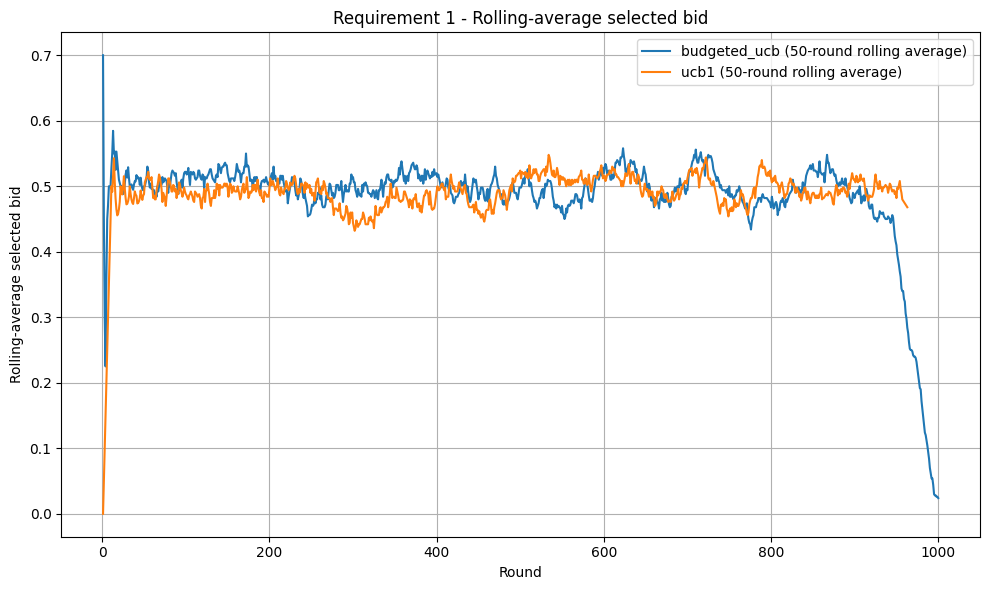

Plots directory: /Users/foadzahedilabaf/Projects/ola-project/results/plots
req1_cumulative_reward.png exists: True
req1_budget_left.png exists: True
req1_cumulative_cost.png exists: True
req1_selected_bid.png exists: True
req1_rolling_average_selected_bid.png exists: True


In [22]:
from ola.utils.plotting import generate_standard_req1_plots

plots_dir = PROJECT_ROOT / "results" / "plots"

# Generate the standard project plots.
generate_standard_req1_plots(
    dataframe=combined_results,
    plots_dir=plots_dir,
)

# Add an extra readability plot for selected bids.
# The raw selected-bid plot is correct, but very noisy because it shows every action.
rolling_window = 50

plt.figure(figsize=(10, 6))

for algorithm_name, group in combined_results.groupby("algorithm"):
    sorted_group = group.sort_values("round").copy()
    sorted_group["rolling_average_bid"] = (
        sorted_group["action"]
        .rolling(window=rolling_window, min_periods=1)
        .mean()
    )

    plt.plot(
        sorted_group["round"],
        sorted_group["rolling_average_bid"],
        label=f"{algorithm_name} ({rolling_window}-round rolling average)",
    )

plt.xlabel("Round")
plt.ylabel("Rolling-average selected bid")
plt.title("Requirement 1 - Rolling-average selected bid")
plt.legend()
plt.grid(True)
plt.tight_layout()

rolling_bid_plot_path = plots_dir / "req1_rolling_average_selected_bid.png"
plt.savefig(rolling_bid_plot_path, dpi=200)
plt.show()

expected_plot_files = [
    "req1_cumulative_reward.png",
    "req1_budget_left.png",
    "req1_cumulative_cost.png",
    "req1_selected_bid.png",
    "req1_rolling_average_selected_bid.png",
]

print("Plots directory:", plots_dir)

for filename in expected_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_cumulative_reward.png


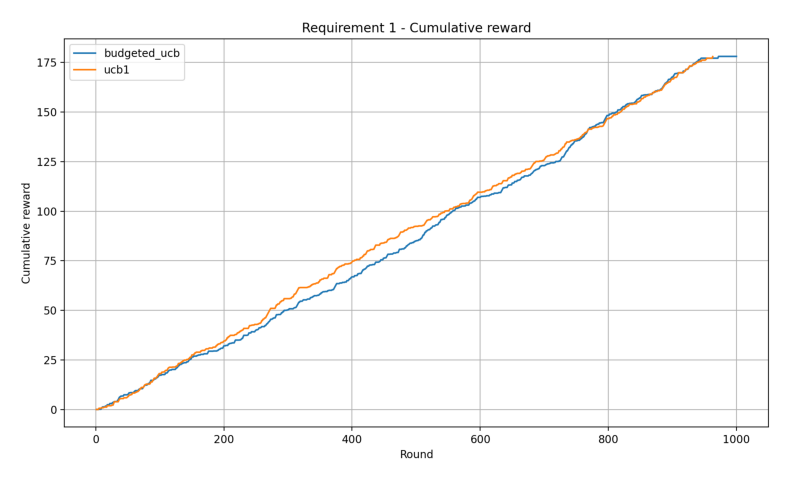

req1_budget_left.png


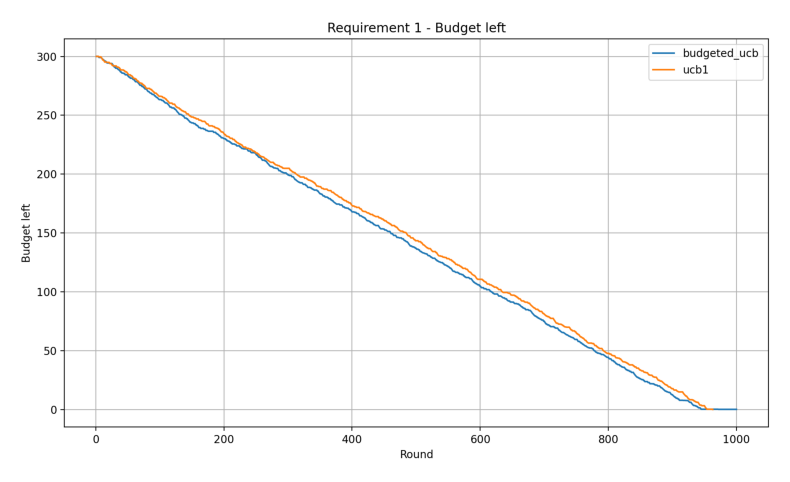

req1_cumulative_cost.png


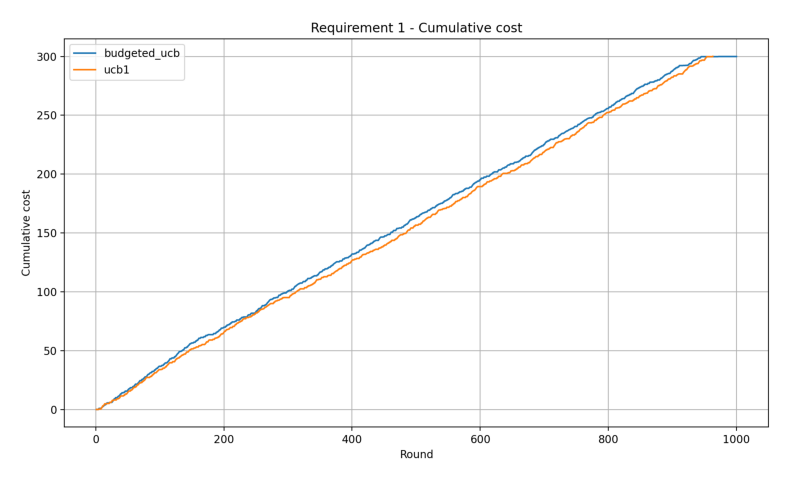

req1_selected_bid.png


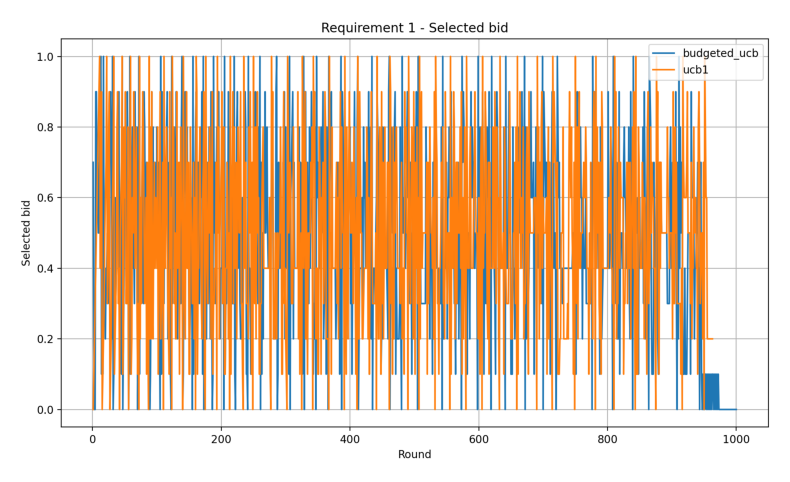

req1_rolling_average_selected_bid.png


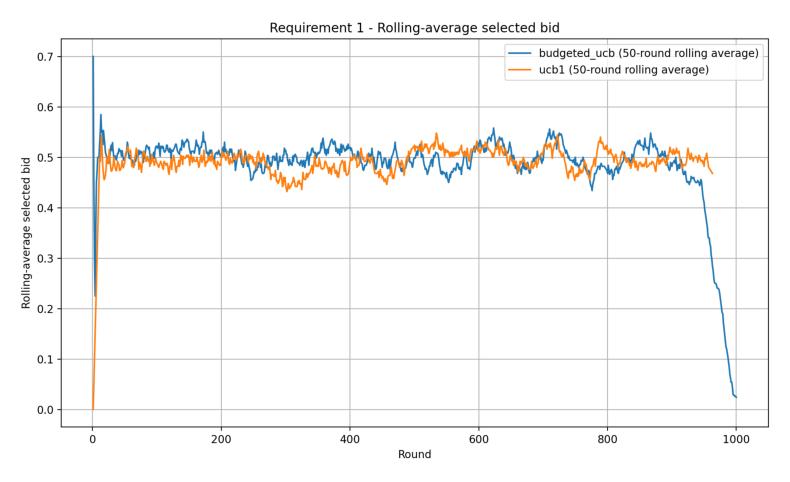

In [25]:
plot_paths = [
    plots_dir / "req1_cumulative_reward.png",
    plots_dir / "req1_budget_left.png",
    plots_dir / "req1_cumulative_cost.png",
    plots_dir / "req1_selected_bid.png",
    plots_dir / "req1_rolling_average_selected_bid.png",
]

for plot_path in plot_paths:
    print(plot_path.name)
    img = plt.imread(plot_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Plot interpretation

The cumulative reward plot shows that UCB1 and Budgeted UCB obtain very similar total rewards.  
This is expected in this configuration because the reward-maximizing bid is also feasible under the expected budget constraint.

The budget-left plot shows the main difference between the two algorithms.  
UCB1 ignores budget pacing and depletes the budget before the end of the horizon.  
Budgeted UCB reaches the full horizon while keeping the budget non-negative.

The cumulative-cost plot confirms the same behavior from the spending perspective.  
UCB1 reaches the total budget earlier, while Budgeted UCB distributes spending more carefully across the whole horizon.

The raw selected-bid plot is noisy because it shows the exact bid selected at every round.  
This is normal for UCB-style algorithms, since they combine exploration and exploitation.

For readability, we also include a 50-round rolling-average selected-bid plot.  
This smoothed plot shows that both algorithms mostly bid around the reward-maximizing region, close to bid 0.5.  
Near the end, Budgeted UCB sharply reduces its selected bid because the remaining budget is very small.  
This is the expected budget-aware behavior.